Premiere exploration des données de Bronchiolite -passage aux urgances

In [2]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [3]:
#pour construire le chemin d'accès aux fichiers de données

from pathlib import Path

raw = Path(r"C:\Users\monik\Documents\3_PRO\3_LEARNING\13_Formation_DATA_SCIENTIST\Projet\Fil_rouge\GitHub\LIORA_PROJET_PATHO_RESPIRATOIRES\notebooks")

print(list(raw.iterdir()))

[WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/01a.Exploration_asthme_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/01b.Exploration_visuelle_asthme_MLU2.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/02a.Exploration_allergie_MLU .ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/02b.Exploration_visuelle_allergie_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/03a.Exploration_bronchiolite_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3

In [4]:
#pour construire le chemin d'accès aux fichiers de données

from pathlib import Path

raw = Path("../data/raw")

# Afficher tous les fichiers CSV, y compris dans les sous-dossiers
for fichier in raw.rglob("*.csv"):
    print(fichier)

..\data\raw\allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv
..\data\raw\pollut_20261012084158 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012084855 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012084932 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012085004 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012085038 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\Sante\allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\Sante\asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\Sante\bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv
..\data\raw\Sante\effectifs.csv


In [5]:
df_bronchiolite = pd.read_csv(
    "../data/raw/Sante/bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv"
)
df_bronchiolite.head()

,1er jour de la semaine,Semaine,Classe d'âge,Taux de passages aux urgences pour bronchiolite,Taux d'hospitalisations après passages aux urgences pour bronchiolite,Taux d'actes médicaux SOS médecins pour bronchiolite,Département Code,Département,Région Code,Région
0,2026-09-28,2026-S40,0 an,14285.714286,NaN,NaN,09,Ariège,76,Occitanie
1,2026-09-28,2026-S40,0 an,0.000000,0.000000,NaN,12,Aveyron,76,Occitanie
2,2026-09-28,2026-S40,0 an,5468.750000,8333.333333,9195.402299,14,Calvados,28,Normandie
3,2026-09-28,2026-S40,0 an,0.000000,0.000000,NaN,01,Ain,84,Auvergne et Rhône-Alpes
4,2026-09-28,2026-S40,0 an,7692.307692,0.000000,NaN,05,Hautes-Alpes,93,Provence-Alpes-Côte d'Azur


In [6]:
#info generale sur le dataframe
df_bronchiolite.info()

<class 'pandas.DataFrame'>
RangeIndex: 36280 entries, 0 to 36279
Data columns (total 10 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   1er jour de la semaine                                                 36280 non-null  str    
 1   Semaine                                                                36280 non-null  str    
 2   Classe d'âge                                                           36280 non-null  str    
 3   Taux de passages aux urgences pour bronchiolite                        35282 non-null  float64
 4   Taux d'hospitalisations après passages aux urgences pour bronchiolite  32911 non-null  float64
 5   Taux d'actes médicaux SOS médecins pour bronchiolite                   16081 non-null  float64
 6   Département Code                                                       36280 non-null  str    
 7

In [7]:
#combien de colonne et de lignes
df_bronchiolite.shape

(36280, 10)

Verification la presence des doublons

In [8]:
df_bronchiolite.duplicated()

print(df_bronchiolite.duplicated().sum())

0


Verification des valeurs manquantes

In [9]:
#mesurer les valeurs manquantes : afficher le nombre de valeurs manquantes par colonne
df_bronchiolite.isna().sum()


1er jour de la semaine                                                       0
Semaine                                                                      0
Classe d'âge                                                                 0
Taux de passages aux urgences pour bronchiolite                            998
Taux d'hospitalisations après passages aux urgences pour bronchiolite     3369
Taux d'actes médicaux SOS médecins pour bronchiolite                     20199
Département Code                                                             0
Département                                                                  0
Région Code                                                                  0
Région                                                                       0
dtype: int64

In [10]:
# pourcentage de valeurs manquantes par colonne
df_bronchiolite.isna().mean().mul(100)

1er jour de la semaine                                                    0.000000
Semaine                                                                   0.000000
Classe d'âge                                                              0.000000
Taux de passages aux urgences pour bronchiolite                           2.750827
Taux d'hospitalisations après passages aux urgences pour bronchiolite     9.286108
Taux d'actes médicaux SOS médecins pour bronchiolite                     55.675303
Département Code                                                          0.000000
Département                                                               0.000000
Région Code                                                               0.000000
Région                                                                    0.000000
dtype: float64

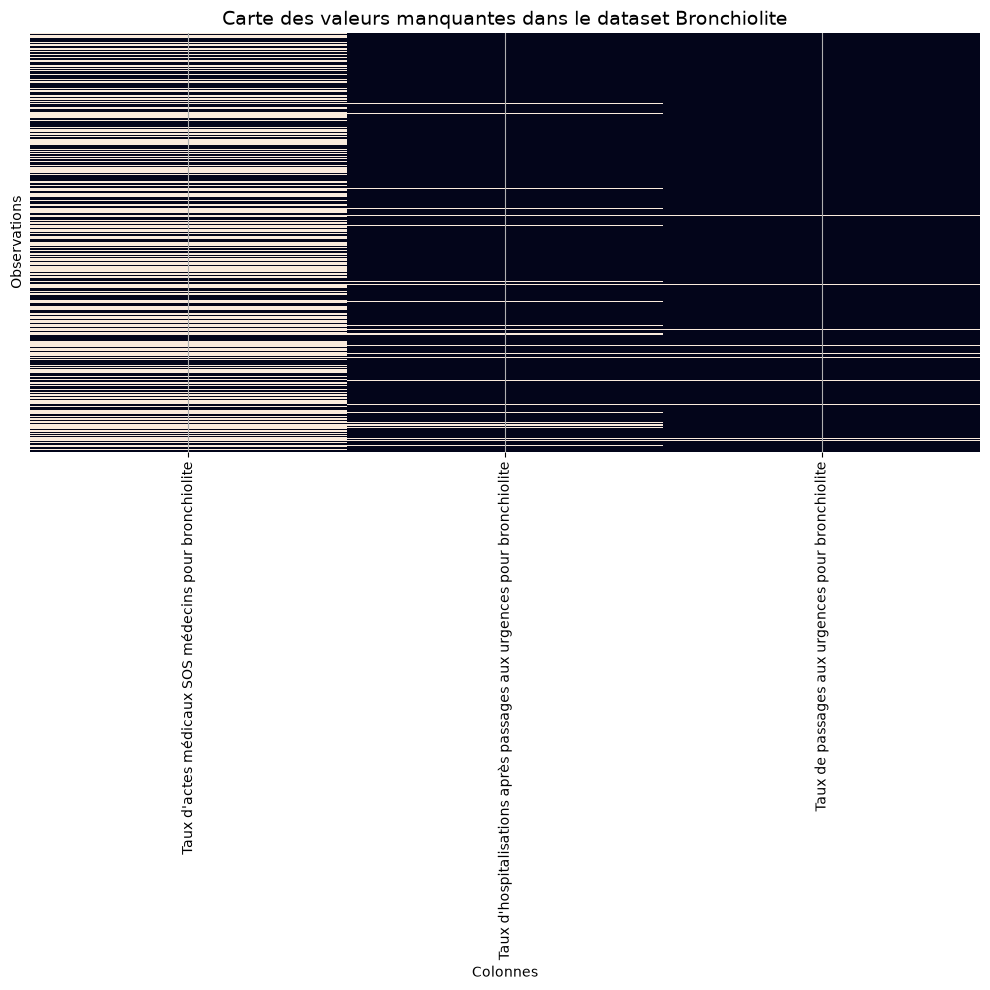

In [11]:
# Affiche le nombre de valeurs manquantes par colonne
missing_values = df_bronchiolite.isna().sum()[lambda x: x > 0].sort_values(ascending=False)      #[lambda x: x > 0] → garde uniquement les colonnes qui ont au moins une valeur manquante.


# Visualisation: Heatmap des valeurs manquantes
plt.figure(figsize=(10, 10))
sns.heatmap(df_bronchiolite[missing_values.index].isna(), cbar=False, yticklabels=False)
plt.title("Carte des valeurs manquantes dans le dataset Bronchiolite", fontsize=14)
plt.xlabel("Colonnes")
plt.ylabel("Observations")
plt.tight_layout()
plt.grid(True)
plt.show()


In [12]:
#afficher les colonnes entierement vides pour les 3 taux cibles
colonnes = ["Taux de passages aux urgences pour bronchiolite", "Taux d'hospitalisations après passages aux urgences pour bronchiolite", "Taux d'actes médicaux SOS médecins pour bronchiolite"]

display(df_bronchiolite[df_bronchiolite[colonnes].isna().all(axis=1)])

,1er jour de la semaine,Semaine,Classe d'âge,Taux de passages aux urgences pour bronchiolite,Taux d'hospitalisations après passages aux urgences pour bronchiolite,Taux d'actes médicaux SOS médecins pour bronchiolite,Département Code,Département,Région Code,Région
9,2026-09-28,2026-S40,0 an,NaN,NaN,NaN,32,Gers,76,Occitanie
338,2026-09-07,2026-S37,0 an,NaN,NaN,NaN,53,Mayenne,52,Pays de la Loire
470,2026-08-31,2026-S36,0 an,NaN,NaN,NaN,53,Mayenne,52,Pays de la Loire
533,2026-08-24,2026-S35,0 an,NaN,NaN,NaN,53,Mayenne,52,Pays de la Loire
1094,2026-07-20,2026-S30,0 an,NaN,NaN,NaN,53,Mayenne,52,Pays de la Loire
...,...,...,...,...,...,...,...,...,...,...
36192,2019-12-30,2020-S01,0 an,NaN,NaN,NaN,978,Saint-Martin,978,Saint-Martin
36243,2019-12-30,2020-S01,0 an,NaN,NaN,NaN,90,Territoire de Belfort,27,Bourgogne et Franche-Comté
36257,2019-12-30,2020-S01,0 an,NaN,NaN,NaN,975,Miquelon-Langlade et Saint Pierre,975,Miquelon-Langlade et Saint Pierre
36259,2019-12-30,2020-S01,0 an,NaN,NaN,NaN,977,Saint-Barthélemy,977,Saint-Barthélemy


In [13]:
#afficher les régions et semaines uniques parmi les lignes où toutes tes colonnes sélectionnées sont NaN :

df_missing = df_bronchiolite[df_bronchiolite[colonnes].isna().all(axis=1)]

print("Régions :", df_missing["Région Code"].unique())
print("Semaines :", sorted(df_missing["Semaine"].dropna().unique()))

Régions : [ 76  52  75  24 977 975 978  84   2  27  32  28  44]
Semaines : ['2020-S01', '2020-S02', '2020-S03', '2020-S04', '2020-S05', '2020-S06', '2020-S07', '2020-S08', '2020-S09', '2020-S10', '2020-S11', '2020-S12', '2020-S13', '2020-S14', '2020-S15', '2020-S16', '2020-S17', '2020-S18', '2020-S19', '2020-S20', '2020-S21', '2020-S22', '2020-S23', '2020-S24', '2020-S25', '2020-S26', '2020-S27', '2020-S28', '2020-S29', '2020-S30', '2020-S31', '2020-S32', '2020-S33', '2020-S34', '2020-S35', '2020-S36', '2020-S37', '2020-S38', '2020-S39', '2020-S40', '2020-S41', '2020-S42', '2020-S43', '2020-S44', '2020-S45', '2020-S46', '2020-S47', '2020-S48', '2020-S49', '2020-S50', '2020-S51', '2020-S52', '2020-S53', '2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06', '2021-S07', '2021-S08', '2021-S09', '2021-S10', '2021-S11', '2021-S12', '2021-S13', '2021-S14', '2021-S15', '2021-S16', '2021-S17', '2021-S18', '2021-S19', '2021-S20', '2021-S21', '2021-S22', '2021-S23', '2021-S24', 

In [14]:
codes = [977, 975, 978]

# Semaines pour les régions 977, 975, 978 avec valeurs manquantes
print("Régions 977, 975, 978 :")
print(sorted(df_missing.loc[df_missing["Région Code"].isin(codes), "Semaine"].unique()))

# Semaines pour toutes les autres régions avec valeurs manquantes
print("\nAutres régions :")
print(sorted(df_missing.loc[~df_missing["Région Code"].isin(codes), "Semaine"].unique()))

Régions 977, 975, 978 :
['2020-S01', '2020-S02', '2020-S03', '2020-S04', '2020-S05', '2020-S06', '2020-S07', '2020-S08', '2020-S09', '2020-S10', '2020-S11', '2020-S12', '2020-S13', '2020-S14', '2020-S15', '2020-S16', '2020-S17', '2020-S18', '2020-S19', '2020-S20', '2020-S21', '2020-S22', '2020-S23', '2020-S24', '2020-S25', '2020-S26', '2020-S27', '2020-S28', '2020-S29', '2020-S30', '2020-S31', '2020-S32', '2020-S33', '2020-S34', '2020-S35', '2020-S36', '2020-S37', '2020-S38', '2020-S39', '2020-S40', '2020-S41', '2020-S42', '2020-S43', '2020-S44', '2020-S45', '2020-S46', '2020-S47', '2020-S48', '2020-S49', '2020-S50', '2020-S51', '2020-S52', '2020-S53', '2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06', '2021-S07', '2021-S08', '2021-S09', '2021-S10', '2021-S11', '2021-S12', '2021-S13', '2021-S14', '2021-S15', '2021-S16', '2021-S17', '2021-S18', '2021-S19', '2021-S20', '2021-S21', '2021-S22', '2021-S23', '2021-S24', '2021-S25', '2021-S26', '2021-S27', '2021-S28', '20

In [19]:
codes = [975, 977, 978]

df_missing_DOM = df_bronchiolite[
    df_bronchiolite[colonnes].isna().all(axis=1)
]

print(
    df_missing_DOM[
        df_missing_DOM["Région Code"].isin(codes)
    ]["Région Code"].value_counts()
)

Région Code
977    209
975    209
978    209
Name: count, dtype: int64


In [ ]:
# Filtrer les semaines entre 2021 et 2024 inclus pour voir si il y en a beaucoup qui manquent
df_periode = df_missing[
    df_missing["Semaine"].str[:4].astype(int).between(2021, 2024)
]

codes = [977, 975, 978]

# Régions 977, 975, 978
print("Régions 977, 975, 978 :")
print(sorted(df_periode.loc[df_periode["Région Code"].isin(codes), "Semaine"].unique()))

# Autres régions
print("\nAutres régions :")
print(sorted(df_periode.loc[~df_periode["Région Code"].isin(codes), "Semaine"].unique()))

Régions 977, 975, 978 :
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06', '2021-S07', '2021-S08', '2021-S09', '2021-S10', '2021-S11', '2021-S12', '2021-S13', '2021-S14', '2021-S15', '2021-S16', '2021-S17', '2021-S18', '2021-S19', '2021-S20', '2021-S21', '2021-S22', '2021-S23', '2021-S24', '2021-S25', '2021-S26', '2021-S27', '2021-S28', '2021-S29', '2021-S30', '2021-S31', '2021-S32', '2021-S33', '2021-S34', '2021-S35', '2021-S36', '2021-S37', '2021-S38', '2021-S39', '2021-S40', '2021-S41', '2021-S42', '2021-S43', '2021-S44', '2021-S45', '2021-S46', '2021-S47', '2021-S48', '2021-S49', '2021-S50', '2021-S51', '2021-S52', '2022-S01', '2022-S02', '2022-S03', '2022-S04', '2022-S05', '2022-S06', '2022-S07', '2022-S08', '2022-S09', '2022-S10', '2022-S11', '2022-S12', '2022-S13', '2022-S14', '2022-S15', '2022-S16', '2022-S17', '2022-S18', '2022-S19', '2022-S20', '2022-S21', '2022-S22', '2022-S23', '2022-S24', '2022-S25', '2022-S26', '2022-S27', '2022-S28', '2022-S29', '20

In [ ]:
#vérifier si toutes les semaines d'une année (2021–2024) figurent parmi les semaines avec valeurs manquantes,
codes = [977, 975, 978]

for nom, filtre in [
    ("Régions 977, 975, 978", df_periode["Région Code"].isin(codes)),
    ("Autres régions", ~df_periode["Région Code"].isin(codes))
]:
    semaines = df_periode.loc[filtre, "Semaine"].dropna().unique()

    print(f"\n{nom}")

    for annee in range(2021, 2025):
        nb = sum(s.startswith(str(annee) + "-S") for s in semaines)
        print(f"{annee} : {nb}/52 semaines avec NaN")


Régions 977, 975, 978
2021 : 52/52 semaines avec NaN
2022 : 52/52 semaines avec NaN
2023 : 52/52 semaines avec NaN
2024 : 0/52 semaines avec NaN

Autres régions
2021 : 27/52 semaines avec NaN
2022 : 2/52 semaines avec NaN
2023 : 3/52 semaines avec NaN
2024 : 21/52 semaines avec NaN


In [ ]:
#Valeurs uniques par colonnes
colonnes = df_bronchiolite.columns.tolist()
df_bronchiolite[colonnes].nunique()

1er jour de la semaine                                                    353
Semaine                                                                   353
Classe d'âge                                                                1
Taux de passages aux urgences pour bronchiolite                          6341
Taux d'hospitalisations après passages aux urgences pour bronchiolite    1775
Taux d'actes médicaux SOS médecins pour bronchiolite                     1614
Département Code                                                          104
Département                                                               104
Région Code                                                                21
Région                                                                     21
dtype: int64

In [ ]:
#quelles sont les valeurs uniques dans la colonne "Classe d'âge"
df_bronchiolite["Classe d'âge"].unique()

<StringArray>
['0 an']
Length: 1, dtype: str

Verification des departements et regions (101 vs 104 et 18 vs 21)

In [ ]:
print("Départements :", sorted(df_bronchiolite["Département Code"].dropna().unique()))
print("Régions :", sorted(df_bronchiolite["Région Code"].dropna().unique()))

Départements : ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '21', '22', '23', '24', '25', '26', '27', '28', '29', '2A', '2B', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '971', '972', '973', '974', '975', '976', '977', '978']
Régions : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(11), np.int64(24), np.int64(27), np.int64(28), np.int64(32), np.int64(44), np.int64(52), np.int64(53), np.int64(75), np.int64(76), np.int64(84), np.int64(93), np.int64(94), np.int64(975), np.int64(977), np.int64(978)]


In [ ]:
#Statistiques descriptives pour la colonne "Taux de passages aux urgences pour bronchiolite"
df_bronchiolite["Taux de passages aux urgences pour bronchiolite"].describe()

count     35282.000000
mean       9222.219282
std        9298.822367
min           0.000000
25%        2338.273949
50%        6821.164400
75%       13048.797787
max      100000.000000
Name: Taux de passages aux urgences pour bronchiolite, dtype: float64

In [ ]:
#Statistiques descriptives pour la colonne "Taux d'hospitalisations après passages aux urgences pour bronchiolite"
df_bronchiolite["Taux d'hospitalisations après passages aux urgences pour bronchiolite"].describe()

count     32911.000000
mean      18354.797667
std       19773.936710
min           0.000000
25%           0.000000
50%       13333.333333
75%       28571.428571
max      100000.000000
Name: Taux d'hospitalisations après passages aux urgences pour bronchiolite, dtype: float64

In [ ]:
#Statistiques descriptives pour la colonne "Taux d'actes médicaux SOS médecins pour bronchiolite" 
df_bronchiolite["Taux d'actes médicaux SOS médecins pour bronchiolite"].describe()

count     16081.000000
mean       6061.418464
std        6577.079040
min           0.000000
25%           0.000000
50%        4545.454545
75%        8988.764045
max      100000.000000
Name: Taux d'actes médicaux SOS médecins pour bronchiolite, dtype: float64

In [ ]:
#Valeurs manquantes par département pour la colonne "Taux d'actes médicaux SOS médecins pour bronchiolite"
manquant1 = df_bronchiolite["Taux d'actes médicaux SOS médecins pour bronchiolite"].isna()

taux_manquants = (
    manquant1.groupby(df_bronchiolite["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
01    100.0
03    100.0
04    100.0
05    100.0
08    100.0
      ...  
73      0.0
75      0.0
76      0.0
89      0.0
91      0.0
Name: Taux d'actes médicaux SOS médecins pour bronchiolite, Length: 104, dtype: float64

In [ ]:
#Valeurs manquantes par département pour la colonne "Taux d'hospitalisations après passages aux urgences pour bronchiolite"
manquant2 = df_bronchiolite["Taux d'hospitalisations après passages aux urgences pour bronchiolite"].isna()

taux_manquants = (
    manquant2.groupby(df_bronchiolite["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
978    100.000000
975    100.000000
977    100.000000
23      82.152975
19      58.923513
          ...    
92       0.000000
88       0.000000
974      0.000000
971      0.000000
973      0.000000
Name: Taux d'hospitalisations après passages aux urgences pour bronchiolite, Length: 104, dtype: float64

In [ ]:
#Valeurs manquantes par département pour la colonne "Taux de passages aux urgences pour bronchiolite"
manquant3 = df_bronchiolite["Taux de passages aux urgences pour bronchiolite"].isna()

taux_manquants = (
    manquant3.groupby(df_bronchiolite   ["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
978    100.000000
975    100.000000
977    100.000000
972     50.424929
53      16.997167
          ...    
92       0.000000
974      0.000000
973      0.000000
971      0.000000
976      0.000000
Name: Taux de passages aux urgences pour bronchiolite, Length: 104, dtype: float64

Verification la coherence  des colonnes redondantes

In [ ]:
#comparer si "Semaine" correspond à "1er jour de la semaine" pour chaque ligne :
#0 je fais un copie pour pas modifier l'originale df_bronchiolite
df_bronchiolite2 = df_bronchiolite.copy()
# 1. Tranformation de la date en numero de semaine
# nettoyage
df_bronchiolite2.columns = (
    df_bronchiolite2.columns
    .str.replace(" ", "_")
    .str.strip()
)

df_bronchiolite2.info()

#2. Transformation de la colonne "1er_jour_de_la_semaine" en datetime (date impossible devient NaT, valeur manquant)
col_date = "1er_jour_de_la_semaine"

dates = pd.to_datetime(
    df_bronchiolite2[col_date], format="%Y-%m-%d", errors="coerce"
)

#extraire l'année et la semaine de la date
iso = dates.dt.isocalendar()

#reconstruction de la meme format que la colonne "Semaine" : "YYYY-SWW"
semaine_calculee = (
    iso["year"].astype("string")
    + "-S"
    + iso["week"].astype("string").str.zfill(2)
)


semaine_source = df_bronchiolite["Semaine"]

#Verification
valide = (
    semaine_source.notna()                      #La semaine est renseignée
    & dates.notna()                             #La date est present et pu etre convertie  
    & semaine_source.eq(semaine_calculee)       #La semaine correspond à la date
    & dates.dt.dayofweek.eq(0)                  #La date est un lundi (0 = lundi, 1 = mardi, ..., 6 = dimanche)
).fillna(False)

print(f"{valide.sum()} lignes cohérentes sur {len(df_bronchiolite2)}")




<class 'pandas.DataFrame'>
RangeIndex: 36280 entries, 0 to 36279
Data columns (total 10 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   1er_jour_de_la_semaine                                                 36280 non-null  str    
 1   Semaine                                                                36280 non-null  str    
 2   Classe_d'âge                                                           36280 non-null  str    
 3   Taux_de_passages_aux_urgences_pour_bronchiolite                        35282 non-null  float64
 4   Taux_d'hospitalisations_après_passages_aux_urgences_pour_bronchiolite  32911 non-null  float64
 5   Taux_d'actes_médicaux_SOS_médecins_pour_bronchiolite                   16081 non-null  float64
 6   Département_Code                                                       36280 non-null  str    
 7

In [ ]:

#comparer si Region correspond à Région Code pour chaque ligne 
    #Est-ce que chaque nom de région possède un seul code ?
    #Est-ce que chaque code possède un seul nom de région ?

#creation tableau de travail
paires = df_bronchiolite2[["Région", "Région_Code"]].copy()

#pour chaque colonne on transforme en texte, retire les espaces et remplace les valeurs vides par NaN si applicable
for col in ["Région", "Région_Code"]:
    paires[col] = (
        paires[col].astype("string").str.strip().replace("", pd.NA)
    )


#Garder les associations distinctes et complètes et on retire les repetitions des lignes entieres pour ne garder que les paires uniques
# Garder une seule fois chaque association région / code
paires = df_bronchiolite2[
    ["Région", "Région_Code"]
].drop_duplicates()

# Chercher les noms associés à plusieurs codes
# ou les codes associés à plusieurs noms
conflits = paires[
    paires.duplicated("Région", keep=False)
    | paires.duplicated("Région_Code", keep=False)
]

display(conflits)



,Région,Région_Code


In [ ]:
#comparer si Département correspond à Département Code pour chaque ligne

    #Est-ce que chaque nom de département possède un seul code ?
    #Est-ce que chaque code possède un seul nom de departement ?

#creation tableau de travail
paires = df_bronchiolite2[["Département", "Département_Code"]].copy()

#pour chaque colonne on transforme en texte, retire les espaces et remplace les valeurs vides par NaN si applicable
for col in ["Département", "Département_Code"]:
    paires[col] = (
        paires[col].astype("string").str.strip().replace("", pd.NA)
    )


#Garder les associations distinctes et complètes et on retire les repetitions des lignes entieres pour ne garder que les paires uniques
# Garder une seule fois chaque association département / code
paires = df_bronchiolite2[
    ["Département", "Département_Code"]
].drop_duplicates()

# Chercher les noms associés à plusieurs codes
# ou les codes associés à plusieurs noms
conflits = paires[
    paires.duplicated("Département", keep=False)
    | paires.duplicated("Département_Code", keep=False)
]

display(conflits)


,Département,Département_Code


Lignes avec une information manquante : 0
Paires impliquées dans une correspondance ambiguë : 0

Attention! Cela ne garantit pas que les codes sont officiellement corrects. Une mauvaise association répétée partout passerait ce contrôle. La vérification officielle nécessite un référentiel adapté à la période des données.